# LogiTrack — Validação de Dados (Python + BigQuery + Great Expectations)

Notebook de conexão e preparação. Nele vamos: (1) conectar o Python ao BigQuery, (2) testar a conexão com uma consulta, (3) carregar as 5 tabelas em DataFrames do Pandas e (4) deixar o Great Expectations pronto para as validações do Desafio 3.

## 1. Instalação dos pacotes

Rode esta célula **uma vez**. Depois de instalar, **reinicie o kernel** (Kernel → Restart) e siga para a próxima célula.

In [3]:
# Instala os pacotes necessários.
# A versão 0.18.22 mantém a API simples usada nas células de validação abaixo.
!pip install -q -U google-cloud-bigquery db-dtypes pandas matplotlib seaborn "great_expectations==0.18.22" "protobuf<7"

^C


  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [19 lines of output]
      + C:\Users\Baian\AppData\Local\Programs\Python\Python313\python.exe C:\Users\Baian\AppData\Local\Temp\pip-install-8520ynx_\numpy_fe4becd83604458bae1582ffc4f61a01\vendored-meson\meson\meson.py setup C:\Users\Baian\AppData\Local\Temp\pip-install-8520ynx_\numpy_fe4becd83604458bae1582ffc4f61a01 C:\Users\Baian\AppData\Local\Temp\pip-install-8520ynx_\numpy_fe4becd83604458bae1582ffc4f61a01\.mesonpy-xy3uqnjo -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --native-file=C:\Users\Baian\AppData\Local\Temp\pip-install-8520ynx_\numpy_fe4becd83604458bae1582ffc4f61a01\.mesonpy-xy3uqnjo\meson-python-native-file.ini
      The Meson build system
      Version: 1.2.99
      Source dir: C:\Users\Baian\AppData\Local\Temp\pip-install-8520ynx_\numpy_fe4becd83604458bae1582ffc4f61a01
      Build dir: C:\Users\Baian\AppData\Local\Temp\pip-install-852

## 2. Imports

In [4]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from google.cloud import bigquery

warnings.filterwarnings('ignore')
print('Imports OK')

Imports OK


## 3. Configuração e conexão com o BigQuery

**Como autenticar (escolha uma opção):**

- **Opção A — arquivo de credenciais (como nas aulas):** no Google Cloud, vá em *IAM e administrador → Contas de serviço*, crie uma conta com os papéis **Usuário de job do BigQuery** e **Leitor de dados do BigQuery**, gere uma chave JSON e coloque o caminho do arquivo em `CREDENTIALS_PATH` abaixo.
- **Opção B — login direto:** deixe `CREDENTIALS_PATH = ""` e, no terminal, rode `gcloud auth application-default login` (precisa do Google Cloud CLI instalado).

In [5]:
# ===== CONFIGURAÇÃO =====
PROJECT_ID = "addrafa"   # projeto do BigQuery
DATASET = "Prova"        # dataset onde estão as 5 tabelas

# Opção A: caminho do JSON da conta de serviço. Ex.: r"C:\Users\Rafael\Downloads\credencial.json"
# Opção B: deixe vazio ("") para usar o login do gcloud.
CREDENTIALS_PATH = ""

if CREDENTIALS_PATH:
    os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = CREDENTIALS_PATH

In [6]:
import pydata_google_auth

# Abre o navegador para você entrar com a conta Google que tem acesso ao projeto
credentials = pydata_google_auth.get_user_credentials(
    ["https://www.googleapis.com/auth/bigquery"],
)
client = bigquery.Client(project=PROJECT_ID, credentials=credentials)
print(f"Cliente criado para o projeto: {client.project}")

Cliente criado para o projeto: addrafa


## 4. Teste de conexão

Consulta simples: se retornar **15000**, a conexão com a tabela fato está funcionando.

In [7]:
query_teste = f"""
    SELECT COUNT(*) AS total_linhas
    FROM `{PROJECT_ID}.{DATASET}.fato_entregas`
"""
df_teste = client.query(query_teste).to_dataframe(create_bqstorage_client=False)
print(df_teste)
print("Conectado ao BigQuery")

   total_linhas
0         15000
Conectado ao BigQuery


## 5. Carregando as 5 tabelas em DataFrames

In [8]:
def carregar_tabela(nome):
    """Lê uma tabela inteira do BigQuery e devolve um DataFrame do Pandas."""
    sql = f"SELECT * FROM `{PROJECT_ID}.{DATASET}.{nome}`"
    return client.query(sql).to_dataframe(create_bqstorage_client=False)

df_fato           = carregar_tabela("fato_entregas")
df_cliente        = carregar_tabela("dim_cliente")
df_transportadora = carregar_tabela("dim_transportadora")
df_regiao         = carregar_tabela("dim_regiao")
df_data           = carregar_tabela("dim_data")

for nome, df in {"fato_entregas": df_fato, "dim_cliente": df_cliente,
                 "dim_transportadora": df_transportadora, "dim_regiao": df_regiao,
                 "dim_data": df_data}.items():
    print(f"{nome:20s} -> {df.shape[0]:>6} linhas x {df.shape[1]} colunas")

fato_entregas        ->  15000 linhas x 10 colunas
dim_cliente          ->    800 linhas x 4 colunas
dim_transportadora   ->      5 linhas x 3 colunas
dim_regiao           ->     10 linhas x 4 colunas
dim_data             ->    181 linhas x 6 colunas


In [9]:
# Conferência rápida da tabela fato
df_fato.head()

,id_entrega,id_cliente,id_transportadora,id_regiao,id_data,prazo_prometido_dias,prazo_real_dias,valor_frete,custo_operacional,status_entrega
0,1848,29,1,1,20260422,3,<NA>,74.24,55.83,Entregue
1,2256,81,2,1,20260612,2,<NA>,63.99,51.41,Entregue
2,6350,531,5,1,20260101,7,<NA>,97.12,68.67,Entregue
3,7153,600,2,1,20260614,5,<NA>,29.21,21.90,Entregue
4,12122,195,1,1,20260430,4,<NA>,72.26,60.96,Entregue


In [10]:
# Tipos de dados e nulos da tabela fato
print(df_fato.dtypes)
print()
print(df_fato.isna().sum())

id_entrega                Int64
id_cliente                Int64
id_transportadora         Int64
id_regiao                 Int64
id_data                   Int64
prazo_prometido_dias      Int64
prazo_real_dias           Int64
valor_frete             float64
custo_operacional       float64
status_entrega              str
dtype: object

id_entrega               0
id_cliente               0
id_transportadora        0
id_regiao                0
id_data                  0
prazo_prometido_dias     0
prazo_real_dias         65
valor_frete             55
custo_operacional        0
status_entrega           0
dtype: int64


## 7. Validações de qualidade com Great Expectations

As regras abaixo seguem o enunciado: unicidade de `id_entrega`, ausência de nulos em `prazo_real_dias`, `custo_operacional > 0` e `prazo_prometido_dias > 0`.

A nota técnica pede que custos nulos também sejam discutidos. Por isso, além das expectativas do Great Expectations, o relatório conta explicitamente os nulos. Valores nulos em prazos também serão reportados como problemáticos.

In [11]:

import great_expectations as gx

print("Versão do Great Expectations:", gx.__version__)


Versão do Great Expectations: 1.24.1


In [12]:

import great_expectations as gx

# 1. Verificar se as colunas necessárias existem
colunas_obrigatorias = [
    "id_entrega",
    "prazo_real_dias",
    "custo_operacional",
    "prazo_prometido_dias"
]

faltantes = [
    coluna for coluna in colunas_obrigatorias
    if coluna not in df_fato.columns
]

if faltantes:
    raise ValueError(f"Colunas ausentes em df_fato: {faltantes}")

# 2. Criar o contexto do Great Expectations
context = gx.get_context()

# 3. Criar uma fonte de dados Pandas
fonte = context.data_sources.add_pandas(
    name="logitrack_fonte"
)

# 4. Criar um ativo para o DataFrame
ativo = fonte.add_dataframe_asset(
    name="fato_entregas"
)

# 5. Criar a definição do lote de dados
lote_definicao = ativo.add_batch_definition_whole_dataframe(
    name="lote_entregas"
)

# 6. Obter o lote utilizando o DataFrame existente
lote = lote_definicao.get_batch(
    batch_parameters={"dataframe": df_fato.copy()}
)

# 7. Validação 1: unicidade de id_entrega
resultado_unicidade = lote.validate(
    gx.expectations.ExpectColumnValuesToBeUnique(
        column="id_entrega"
    )
)

# 8. Validação 2: ausência de nulos em prazo_real_dias
resultado_prazo_real = lote.validate(
    gx.expectations.ExpectColumnValuesToNotBeNull(
        column="prazo_real_dias"
    )
)

# 9. Validação 3: custo_operacional estritamente maior que zero
resultado_custo = lote.validate(
    gx.expectations.ExpectColumnValuesToBeBetween(
        column="custo_operacional",
        min_value=0,
        strict_min=True
    )
)

# 10. Validação 4: prazo_prometido_dias estritamente maior que zero
resultado_prazo_prometido = lote.validate(
    gx.expectations.ExpectColumnValuesToBeBetween(
        column="prazo_prometido_dias",
        min_value=0,
        strict_min=True
    )
)

# 11. Exibir o resultado das quatro validações
validacoes = {
    "Unicidade de id_entrega": resultado_unicidade,
    "Ausência de nulos em prazo_real_dias": resultado_prazo_real,
    "Custo operacional > 0": resultado_custo,
    "Prazo prometido > 0": resultado_prazo_prometido
}

for nome, resultado in validacoes.items():
    status = "APROVADA" if resultado.success else "REPROVADA"
    print(f"{nome}: {status}")

print("\nTotal de registros avaliados:", len(df_fato))


Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 485.18it/s]

Unicidade de id_entrega: REPROVADA
Ausência de nulos em prazo_real_dias: REPROVADA
Custo operacional > 0: REPROVADA
Prazo prometido > 0: REPROVADA

Total de registros avaliados: 15000


## 8. Quantificação dos registros problemáticos

Esta célula conta os problemas diretamente no Pandas, incluindo valores nulos que algumas expectativas numéricas podem ignorar.

In [ ]:
import pandas as pd
from datetime import datetime

# Quantificar os registros problemáticos
total_registros = len(df_fato)

problemas = {
    "Unicidade de id_entrega": df_fato["id_entrega"].duplicated(keep=False).sum(),
    "Nulos em prazo_real_dias": df_fato["prazo_real_dias"].isna().sum(),
    "Custo operacional menor ou igual a zero": (
        df_fato["custo_operacional"].le(0).fillna(False).sum()
    ),
    "Custo operacional nulo": df_fato["custo_operacional"].isna().sum(),
    "Prazo prometido menor ou igual a zero": (
        df_fato["prazo_prometido_dias"].le(0).fillna(False).sum()
    ),
    "Prazo prometido nulo": df_fato["prazo_prometido_dias"].isna().sum()
}

# Relacionar cada regra ao resultado do Great Expectations
resultados_ge = {
    "Unicidade de id_entrega": resultado_unicidade.success,
    "Ausência de nulos em prazo_real_dias": resultado_prazo_real.success,
    "Custo operacional > 0": resultado_custo.success,
    "Prazo prometido > 0": resultado_prazo_prometido.success
}

# Montar as informações para o relatório
linhas = [
    {
        "Regra": "Unicidade de id_entrega",
        "Status": "APROVADA" if resultados_ge["Unicidade de id_entrega"] else "REPROVADA",
        "Registros problemáticos": problemas["Unicidade de id_entrega"],
        "Critério": "Cada ID de entrega deve ser único."
    },
    {
        "Regra": "Ausência de nulos em prazo_real_dias",
        "Status": "APROVADA" if resultados_ge["Ausência de nulos em prazo_real_dias"] else "REPROVADA",
        "Registros problemáticos": problemas["Nulos em prazo_real_dias"],
        "Critério": "O prazo real não deve conter valores nulos."
    },
    {
        "Regra": "Custo operacional > 0",
        "Status": "APROVADA" if resultados_ge["Custo operacional > 0"] else "REPROVADA",
        "Registros problemáticos": problemas["Custo operacional menor ou igual a zero"],
        "Critério": "O custo operacional deve ser estritamente positivo."
    },
    {
        "Regra": "Prazo prometido > 0",
        "Status": "APROVADA" if resultados_ge["Prazo prometido > 0"] else "REPROVADA",
        "Registros problemáticos": problemas["Prazo prometido menor ou igual a zero"],
        "Critério": "O prazo prometido deve ser estritamente positivo."
    }
]

relatorio = pd.DataFrame(linhas)
relatorio["Percentual problemático (%)"] = (
    relatorio["Registros problemáticos"] / total_registros * 100
).round(2)

# Converter a tabela para HTML
tabela_html = relatorio.to_html(
    index=False,
    border=0,
    classes="tabela",
    escape=True
)

# Criar o relatório HTML
html = f"""
<!DOCTYPE html>
<html lang="pt-BR">
<head>
    <meta charset="UTF-8">
    <title>Relatório de Qualidade dos Dados - LogiTrack</title>
    <style>
        body {{
            font-family: Arial, sans-serif;
            margin: 35px;
            background-color: #f5f7fa;
            color: #263238;
        }}
        h1, h2 {{
            color: #17365d;
        }}
        .resumo {{
            background: white;
            padding: 18px;
            border-radius: 8px;
            margin-bottom: 20px;
        }}
        table {{
            border-collapse: collapse;
            width: 100%;
            background: white;
        }}
        th, td {{
            padding: 12px;
            border: 1px solid #ddd;
            text-align: left;
        }}
        th {{
            background-color: #17365d;
            color: white;
        }}
        .aprovada {{
            color: #18733b;
            font-weight: bold;
        }}
        .reprovada {{
            color: #c62828;
            font-weight: bold;
        }}
        .observacao {{
            margin-top: 20px;
            font-size: 13px;
            color: #555;
        }}
    </style>
</head>
<body>
    <h1>Relatório de Qualidade dos Dados</h1>
    <h2>LogiTrack — Validações com Great Expectations</h2>

    <div class="resumo">
        <p><strong>Data de geração:</strong> {datetime.now().strftime("%d/%m/%Y %H:%M:%S")}</p>
        <p><strong>Total de registros avaliados:</strong> {total_registros:,}</p>
        <p><strong>Regras aprovadas:</strong> {sum(resultados_ge.values())} de 4</p>
        <p><strong>Regras reprovadas:</strong> {4 - sum(resultados_ge.values())} de 4</p>
    </div>

    <h2>Resultado das validações</h2>
    {tabela_html}

    <div class="observacao">
        <p>
            Observação: o percentual de registros problemáticos é calculado
            sobre o total de registros. Um mesmo registro pode apresentar
            mais de um problema. Na regra de unicidade, são contabilizadas
            todas as linhas cujo ID aparece mais de uma vez.
        </p>
        <p>
            Valores nulos em custo operacional e prazo prometido são
            apresentados separadamente. A contagem de valores menores ou
            iguais a zero não inclui os nulos.
        </p>
    </div>
</body>
</html>
"""

# Salvar o relatório
with open("relatorio_qualidade_dados.html", "w", encoding="utf-8") as arquivo:
    arquivo.write(html)

print("Relatório HTML gerado: relatorio_qualidade_dados.html")

Relatório HTML gerado: relatorio_qualidade_dados.html


Desafio 4 

In [13]:

# ============================================================
# DESAFIO 4 — CONSULTAS SQL EXECUTADAS DIRETAMENTE NO BIGQUERY
# Usa a conexão "client" já criada no início do notebook
# ============================================================

# A. Taxa de atraso por macrorregião
sql_regiao = f"""
SELECT
    r.macrorregiao,
    COUNT(*) AS total_entregas,
    COUNTIF(f.prazo_real_dias > f.prazo_prometido_dias) AS entregas_atrasadas,
    ROUND(
        SAFE_DIVIDE(
            COUNTIF(f.prazo_real_dias > f.prazo_prometido_dias),
            COUNT(*)
        ) * 100, 2
    ) AS taxa_atraso_pct
FROM `{PROJECT_ID}.{DATASET}.fato_entregas` AS f
JOIN `{PROJECT_ID}.{DATASET}.dim_regiao` AS r
    ON f.id_regiao = r.id_regiao
WHERE
    f.status_entrega = 'Entregue'
    AND f.prazo_prometido_dias > 0
    AND f.prazo_real_dias IS NOT NULL
GROUP BY r.macrorregiao
ORDER BY taxa_atraso_pct DESC
"""

# B. Evolução mensal da taxa de atraso
sql_mes = f"""
SELECT
    d.ano_mes,
    COUNT(*) AS total_entregas,
    COUNTIF(f.prazo_real_dias > f.prazo_prometido_dias) AS entregas_atrasadas,
    ROUND(
        SAFE_DIVIDE(
            COUNTIF(f.prazo_real_dias > f.prazo_prometido_dias),
            COUNT(*)
        ) * 100, 2
    ) AS taxa_atraso_pct
FROM `{PROJECT_ID}.{DATASET}.fato_entregas` AS f
JOIN `{PROJECT_ID}.{DATASET}.dim_data` AS d
    ON f.id_data = d.id_data
WHERE
    f.status_entrega = 'Entregue'
    AND f.prazo_prometido_dias > 0
    AND f.prazo_real_dias IS NOT NULL
GROUP BY d.ano_mes
ORDER BY d.ano_mes
"""

# Consulta C. Taxa de atraso por transportadora
sql_transportadora = f"""
SELECT
    t.nome_transportadora,
    COUNT(*) AS total_entregas,
    COUNTIF(f.prazo_real_dias > f.prazo_prometido_dias) AS entregas_atrasadas,
    ROUND(
        SAFE_DIVIDE(
            COUNTIF(f.prazo_real_dias > f.prazo_prometido_dias),
            COUNT(*)
        ) * 100, 2
    ) AS taxa_atraso_pct
FROM `{PROJECT_ID}.{DATASET}.fato_entregas` AS f
JOIN `{PROJECT_ID}.{DATASET}.dim_transportadora` AS t
    ON f.id_transportadora = t.id_transportadora
WHERE
    f.status_entrega = 'Entregue'
    AND f.prazo_prometido_dias > 0
    AND f.prazo_real_dias IS NOT NULL
GROUP BY t.nome_transportadora
ORDER BY taxa_atraso_pct DESC
"""

# Consulta D. Taxa de atraso por transportadora e macrorregião
sql_transportadora_regiao = f"""
SELECT
    t.nome_transportadora,
    r.macrorregiao,
    COUNT(*) AS total_entregas,
    COUNTIF(f.prazo_real_dias > f.prazo_prometido_dias) AS entregas_atrasadas,
    ROUND(
        SAFE_DIVIDE(
            COUNTIF(f.prazo_real_dias > f.prazo_prometido_dias),
            COUNT(*)
        ) * 100, 2
    ) AS taxa_atraso_pct
FROM `{PROJECT_ID}.{DATASET}.fato_entregas` AS f
JOIN `{PROJECT_ID}.{DATASET}.dim_transportadora` AS t
    ON f.id_transportadora = t.id_transportadora
JOIN `{PROJECT_ID}.{DATASET}.dim_regiao` AS r
    ON f.id_regiao = r.id_regiao
WHERE
    f.status_entrega = 'Entregue'
    AND f.prazo_prometido_dias > 0
    AND f.prazo_real_dias IS NOT NULL
GROUP BY
    t.nome_transportadora,
    r.macrorregiao
HAVING COUNT(*) >= 100
ORDER BY taxa_atraso_pct DESC
"""

# Executar as consultas no BigQuery e guardar os resultados em DataFrames
df_regiao = client.query(sql_regiao).to_dataframe(create_bqstorage_client=False)
df_mes = client.query(sql_mes).to_dataframe(create_bqstorage_client=False)
df_transportadora = client.query(sql_transportadora).to_dataframe(create_bqstorage_client=False)
df_transportadora_regiao = client.query(sql_transportadora_regiao).to_dataframe(
    create_bqstorage_client=False
)

print("CONSULTA A — TAXA DE ATRASO POR MACRORREGIÃO")
display(df_regiao)

print("\nCONSULTA B — EVOLUÇÃO MENSAL DA TAXA DE ATRASO")
display(df_mes)

print("\nCONSULTA C — TAXA DE ATRASO POR TRANSPORTADORA")
display(df_transportadora)

print("\nCONSULTA D — TRANSPORTADORA E MACRORREGIÃO (mínimo de 100 entregas)")
display(df_transportadora_regiao)



CONSULTA A — TAXA DE ATRASO POR MACRORREGIÃO


,macrorregiao,total_entregas,entregas_atrasadas,taxa_atraso_pct
0,Nordeste,2332,765,32.80
1,Centro-Oeste,2428,368,15.16
2,Sul,3699,558,15.09
3,Sudeste,3547,509,14.35



CONSULTA B — EVOLUÇÃO MENSAL DA TAXA DE ATRASO


,ano_mes,total_entregas,entregas_atrasadas,taxa_atraso_pct
0,2026-01,2077,298,14.35
1,2026-02,1888,298,15.78
2,2026-03,2054,306,14.90
3,2026-04,1988,290,14.59
4,2026-05,2027,514,25.36
5,2026-06,1972,494,25.05



CONSULTA C — TAXA DE ATRASO POR TRANSPORTADORA


,nome_transportadora,total_entregas,entregas_atrasadas,taxa_atraso_pct
0,Rota Brasil,2377,731,30.75
1,Entrega Certa,2412,381,15.80
2,NorteSul Log,2431,384,15.80
3,Veloz Cargo,2350,361,15.36
4,Ágil Express,2436,343,14.08



CONSULTA D — TRANSPORTADORA E MACRORREGIÃO (mínimo de 100 entregas)


,nome_transportadora,macrorregiao,total_entregas,entregas_atrasadas,taxa_atraso_pct
0,Rota Brasil,Nordeste,455,206,45.27
1,Entrega Certa,Nordeste,474,151,31.86
2,Veloz Cargo,Nordeste,465,142,30.54
3,Rota Brasil,Sul,718,219,30.50
4,Ágil Express,Nordeste,468,137,29.27
5,NorteSul Log,Nordeste,470,129,27.45
6,Rota Brasil,Centro-Oeste,512,136,26.56
7,Rota Brasil,Sudeste,692,170,24.57
8,Entrega Certa,Centro-Oeste,489,67,13.70
9,NorteSul Log,Sul,726,98,13.50


Graficos


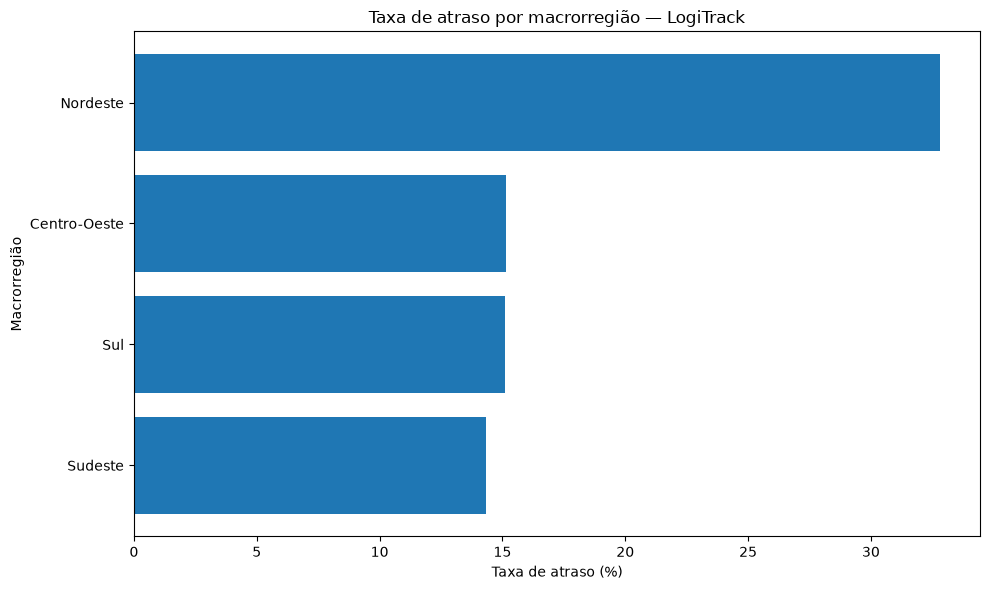

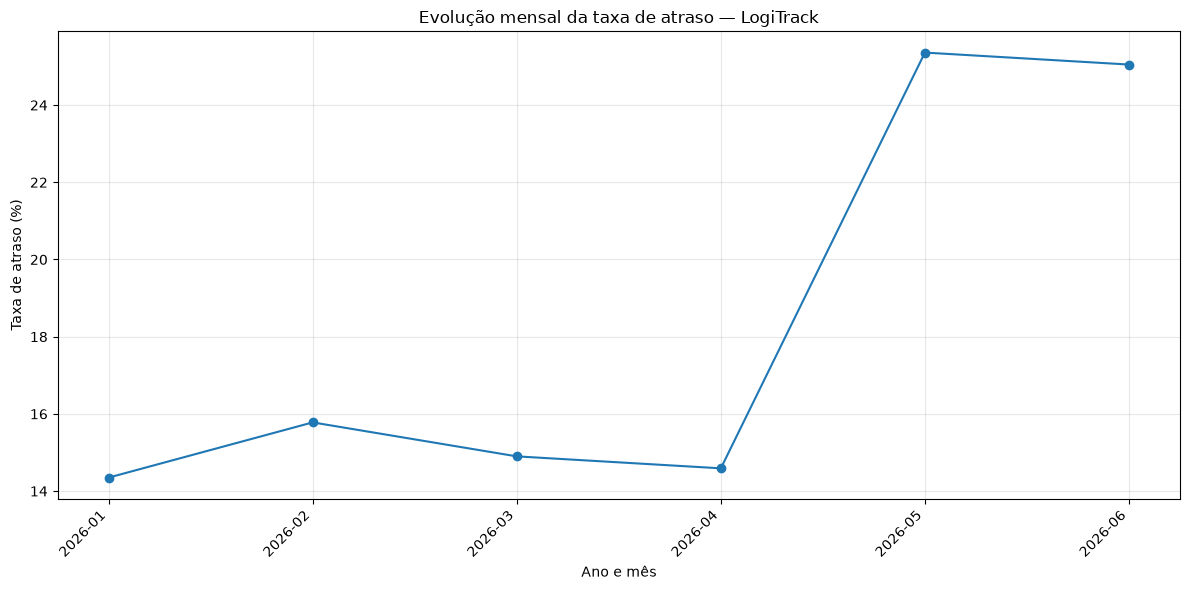

Gráficos salvos:
- grafico_taxa_atraso_macrorregiao.png
- grafico_evolucao_mensal_atrasos.png


In [14]:

# ============================================================
# DESAFIO 4 — GRÁFICOS
# ============================================================

import matplotlib.pyplot as plt

# Gráfico A — Taxa de atraso por macrorregião
if not df_regiao.empty:
    dados_regiao = df_regiao.sort_values("taxa_atraso_pct", ascending=True)

    plt.figure(figsize=(10, 6))
    plt.barh(
        dados_regiao["macrorregiao"].astype(str),
        dados_regiao["taxa_atraso_pct"]
    )
    plt.xlabel("Taxa de atraso (%)")
    plt.ylabel("Macrorregião")
    plt.title("Taxa de atraso por macrorregião — LogiTrack")
    plt.tight_layout()
    plt.savefig("grafico_taxa_atraso_macrorregiao.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("A consulta por macrorregião não retornou resultados.")

# Gráfico B — Evolução mensal da taxa de atraso
if not df_mes.empty:
    dados_mes = df_mes.sort_values("ano_mes")

    plt.figure(figsize=(12, 6))
    plt.plot(
        dados_mes["ano_mes"].astype(str),
        dados_mes["taxa_atraso_pct"],
        marker="o"
    )
    plt.xlabel("Ano e mês")
    plt.ylabel("Taxa de atraso (%)")
    plt.title("Evolução mensal da taxa de atraso — LogiTrack")
    plt.xticks(rotation=45, ha="right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("grafico_evolucao_mensal_atrasos.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("A consulta mensal não retornou resultados.")

print("Gráficos salvos:")
print("- grafico_taxa_atraso_macrorregiao.png")
print("- grafico_evolucao_mensal_atrasos.png")


3 padroes


In [15]:

# ============================================================
# DESAFIO 4 — IDENTIFICAÇÃO AUTOMÁTICA DE PADRÕES
# ============================================================

print("=" * 65)
print("ANÁLISE DOS PADRÕES DE ATRASO — LOGITRACK")
print("=" * 65)

# PADRÃO 1 — Diferença entre macrorregiões
if len(df_regiao) >= 2:
    regiao_maior = df_regiao.loc[df_regiao["taxa_atraso_pct"].idxmax()]
    regiao_menor = df_regiao.loc[df_regiao["taxa_atraso_pct"].idxmin()]

    diferenca_regiao = (
        regiao_maior["taxa_atraso_pct"] - regiao_menor["taxa_atraso_pct"]
    )

    print("\nPADRÃO 1 — DIFERENÇA REGIONAL")
    print(
        f"Maior taxa: {regiao_maior['macrorregiao']} — "
        f"{regiao_maior['taxa_atraso_pct']:.2f}% "
        f"({int(regiao_maior['total_entregas'])} entregas)"
    )
    print(
        f"Menor taxa: {regiao_menor['macrorregiao']} — "
        f"{regiao_menor['taxa_atraso_pct']:.2f}% "
        f"({int(regiao_menor['total_entregas'])} entregas)"
    )
    print(f"Diferença entre as taxas: {diferenca_regiao:.2f} pontos percentuais")

# PADRÃO 2 — Mudança da taxa de atraso ao longo dos meses
if len(df_mes) >= 2:
    dados_mes_ordenados = df_mes.sort_values("ano_mes").reset_index(drop=True)

    mes_maior = dados_mes_ordenados.loc[
        dados_mes_ordenados["taxa_atraso_pct"].idxmax()
    ]
    mes_menor = dados_mes_ordenados.loc[
        dados_mes_ordenados["taxa_atraso_pct"].idxmin()
    ]

    primeiro_mes = dados_mes_ordenados.iloc[0]
    ultimo_mes = dados_mes_ordenados.iloc[-1]

    variacao_periodo = (
        ultimo_mes["taxa_atraso_pct"] - primeiro_mes["taxa_atraso_pct"]
    )

    print("\nPADRÃO 2 — EVOLUÇÃO TEMPORAL")
    print(
        f"Maior taxa mensal: {mes_maior['ano_mes']} — "
        f"{mes_maior['taxa_atraso_pct']:.2f}%"
    )
    print(
        f"Menor taxa mensal: {mes_menor['ano_mes']} — "
        f"{mes_menor['taxa_atraso_pct']:.2f}%"
    )
    print(
        f"Variação entre o primeiro mês ({primeiro_mes['ano_mes']}) "
        f"e o último ({ultimo_mes['ano_mes']}): "
        f"{variacao_periodo:+.2f} pontos percentuais"
    )

# PADRÃO 3 — Diferença entre transportadoras
if len(df_transportadora) >= 2:
    transp_maior = df_transportadora.loc[
        df_transportadora["taxa_atraso_pct"].idxmax()
    ]
    transp_menor = df_transportadora.loc[
        df_transportadora["taxa_atraso_pct"].idxmin()
    ]

    diferenca_transp = (
        transp_maior["taxa_atraso_pct"] - transp_menor["taxa_atraso_pct"]
    )

    print("\nPADRÃO 3 — DIFERENÇA ENTRE TRANSPORTADORAS")
    print(
        f"Maior taxa: {transp_maior['nome_transportadora']} — "
        f"{transp_maior['taxa_atraso_pct']:.2f}% "
        f"({int(transp_maior['total_entregas'])} entregas)"
    )
    print(
        f"Menor taxa: {transp_menor['nome_transportadora']} — "
        f"{transp_menor['taxa_atraso_pct']:.2f}% "
        f"({int(transp_menor['total_entregas'])} entregas)"
    )
    print(f"Diferença entre as taxas: {diferenca_transp:.2f} pontos percentuais")

# ANÁLISE COMPLEMENTAR — Transportadora e região
if not df_transportadora_regiao.empty:
    combinacao_maior = df_transportadora_regiao.loc[
        df_transportadora_regiao["taxa_atraso_pct"].idxmax()
    ]

    print("\nANÁLISE COMPLEMENTAR — COMBINAÇÃO TRANSPORTADORA/REGIÃO")
    print(
        f"Maior taxa entre as combinações com pelo menos 100 entregas: "
        f"{combinacao_maior['nome_transportadora']} em "
        f"{combinacao_maior['macrorregiao']} — "
        f"{combinacao_maior['taxa_atraso_pct']:.2f}% "
        f"({int(combinacao_maior['total_entregas'])} entregas)"
    )

print("\n" + "=" * 65)
print("Análise concluída. Utilize os valores acima para fundamentar o relatório.")


ANÁLISE DOS PADRÕES DE ATRASO — LOGITRACK

PADRÃO 1 — DIFERENÇA REGIONAL
Maior taxa: Nordeste — 32.80% (2332 entregas)
Menor taxa: Sudeste — 14.35% (3547 entregas)
Diferença entre as taxas: 18.45 pontos percentuais

PADRÃO 2 — EVOLUÇÃO TEMPORAL
Maior taxa mensal: 2026-05 — 25.36%
Menor taxa mensal: 2026-01 — 14.35%
Variação entre o primeiro mês (2026-01) e o último (2026-06): +10.70 pontos percentuais

PADRÃO 3 — DIFERENÇA ENTRE TRANSPORTADORAS
Maior taxa: Rota Brasil — 30.75% (2377 entregas)
Menor taxa: Ágil Express — 14.08% (2436 entregas)
Diferença entre as taxas: 16.67 pontos percentuais

ANÁLISE COMPLEMENTAR — COMBINAÇÃO TRANSPORTADORA/REGIÃO
Maior taxa entre as combinações com pelo menos 100 entregas: Rota Brasil em Nordeste — 45.27% (455 entregas)

Análise concluída. Utilize os valores acima para fundamentar o relatório.
